# PCA and Super-Resolution of Satellite Images

## Download EuroSAT dataset

EuroSAT contains 27,000 labelled Sentinel-2 images in 10 land-cover classes; we use the RGB version with 64 × 64 patches and select Forest, Residential and SeaLake (water, including seas and lakes).

Source: [EuroSAT on Zenodo](https://zenodo.org/records/7711810).

In [11]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

IMAGE_DIR = (Path('lab_5') if Path('lab_5').exists() else Path('.')) / 'images'
DATASET_DIR = IMAGE_DIR / 'EuroSAT_RGB'

if not DATASET_DIR.exists():
    IMAGE_DIR.mkdir(exist_ok=True)
    archive_path = IMAGE_DIR / 'EuroSAT_RGB.zip'
    urlretrieve('https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1', archive_path)
    with ZipFile(archive_path) as archive:
        archive.extractall(IMAGE_DIR)

## Dataset preparation

In [12]:
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split

CLASSES = ['Forest', 'Residential', 'SeaLake']
SEED = 42
rng = np.random.default_rng(SEED)
X, y = [], []

for label, name in enumerate(CLASSES):
    files = sorted((DATASET_DIR / name).glob('*.jpg'))
    for path in rng.choice(files, size=500, replace=False):
        with Image.open(path) as image:
            X.append(np.array(image.convert('RGB')))
        y.append(label)

X = np.array(X, dtype=np.float32) / 255.0
y = np.array(y)

X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED,
)
X_validation, X_test, y_validation, y_test = train_test_split(
    X_rest, y_rest, test_size=0.50, stratify=y_rest, random_state=SEED,
)

print('Train:', len(X_train))
print('Validation:', len(X_validation))
print('Test:', len(X_test))

Train: 1050
Validation: 225
Test: 225


## PCA

Shape: (1050, 12288) -> (1050, 3)
Explained variance (%): [79.57  2.09  1.12]
Total explained variance: 82.8%


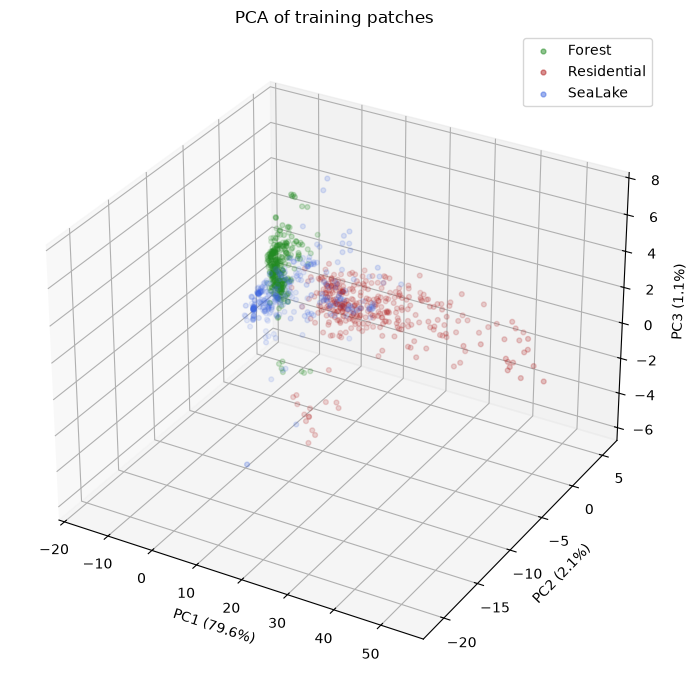

In [13]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

X_flat = X_train.reshape(len(X_train), -1)
pca = PCA(n_components=3, svd_solver='randomized', random_state=SEED)
X_pca = pca.fit_transform(X_flat)

print('Shape:', X_flat.shape, '->', X_pca.shape)
print('Explained variance (%):', np.round(pca.explained_variance_ratio_ * 100, 2))
print(f'Total explained variance: {pca.explained_variance_ratio_.sum():.1%}')

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')
for label, (name, color) in enumerate(zip(CLASSES, ['forestgreen', 'firebrick', 'royalblue'])):
    points = X_pca[y_train == label]
    ax.scatter(points[:, 0], points[:, 1], points[:, 2], label=name, c=color, s=12, alpha=0.5)
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
ax.set_zlabel(f'PC3 ({pca.explained_variance_ratio_[2]:.1%})')
ax.set_title('PCA of training patches')
ax.legend()
plt.tight_layout()
plt.show()

The three components retain 82.8% of variance; classes show partial grouping, with Residential generally shifted along PC1 and some overlap between Forest and SeaLake.

## Prepare super-resolution data

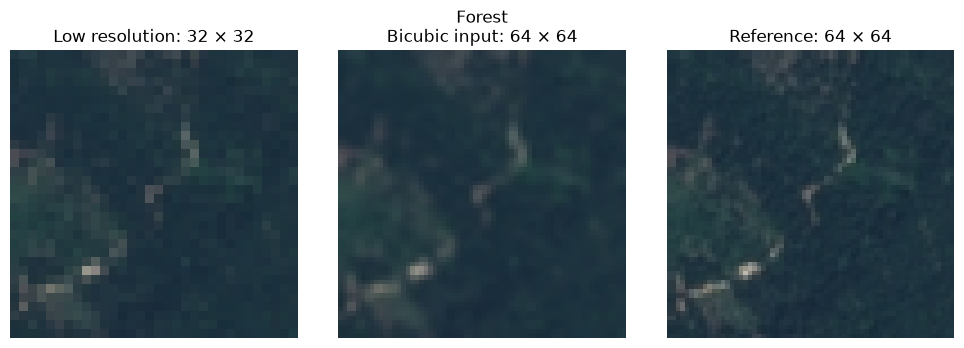

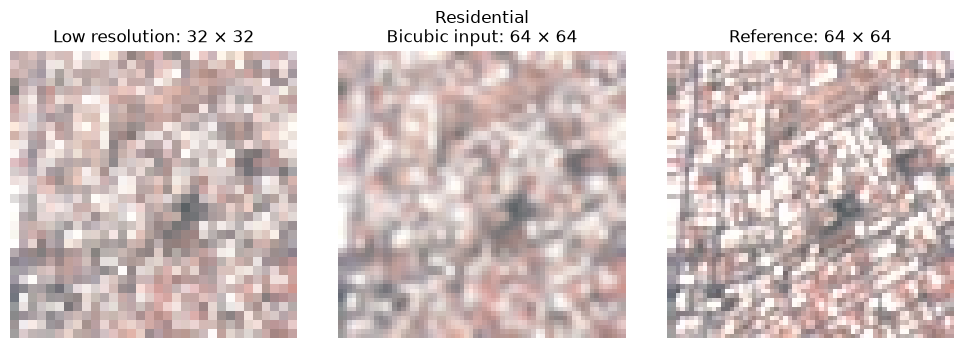

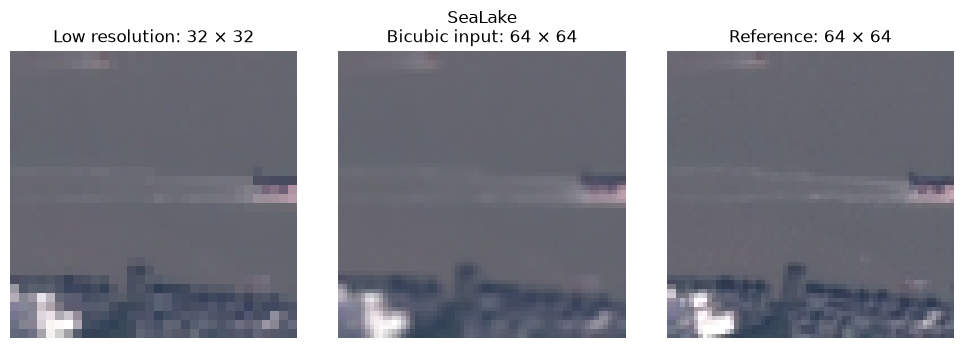

In [14]:
import tensorflow as tf

def prepare_sr(images):
    low = tf.image.resize(images, (32, 32), method='area')
    inputs = tf.image.resize(low, (64, 64), method='bicubic')
    return low.numpy(), np.clip(inputs.numpy(), 0, 1)

def detailed_indices(images, labels, label, count=1):
    indices = np.flatnonzero(labels == label)
    samples = images[indices]
    texture = np.mean(np.abs(np.diff(samples, axis=1)), axis=(1, 2, 3))
    texture += np.mean(np.abs(np.diff(samples, axis=2)), axis=(1, 2, 3))
    return indices[np.argsort(texture)[-count:][::-1]]

low_train, sr_train = prepare_sr(X_train)
low_validation, sr_validation = prepare_sr(X_validation)
low_test, sr_test = prepare_sr(X_test)

for label, name in enumerate(CLASSES):
    index = detailed_indices(X_train, y_train, label)[0]
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
    for ax, (image, title) in zip(axes, [
        (low_train[index], 'Low resolution: 32 × 32'),
        (sr_train[index], 'Bicubic input: 64 × 64'),
        (X_train[index], 'Reference: 64 × 64'),
    ]):
        ax.imshow(image, interpolation='nearest')
        ax.set_title(title)
        ax.axis('off')
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()

## Autoencoder and comparison

A small encoder–decoder learns an MSE-based correction of bicubic input; examples are selected by reference-image texture, while metrics cover all test images.

In [15]:
tf.keras.utils.set_random_seed(SEED)

inputs = tf.keras.Input(shape=(64, 64, 3))
e1 = tf.keras.layers.Conv2D(16, 3, padding='same', activation='relu')(inputs)
e2 = tf.keras.layers.MaxPooling2D()(e1)
e2 = tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu')(e2)
encoded = tf.keras.layers.MaxPooling2D()(e2)
encoded = tf.keras.layers.Conv2D(64, 3, padding='same', activation='relu')(encoded)

decoded = tf.keras.layers.UpSampling2D()(encoded)
decoded = tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu')(decoded)
decoded = tf.keras.layers.Add()([decoded, e2])
decoded = tf.keras.layers.UpSampling2D()(decoded)
decoded = tf.keras.layers.Conv2D(16, 3, padding='same', activation='relu')(decoded)
decoded = tf.keras.layers.Add()([decoded, e1])
correction = tf.keras.layers.Conv2D(3, 3, padding='same', kernel_initializer='zeros')(decoded)
outputs = tf.keras.layers.Add()([inputs, correction])

autoencoder = tf.keras.Model(inputs, outputs)
autoencoder.compile(optimizer=tf.keras.optimizers.Adam(0.001), loss='mse')

In [16]:
history = autoencoder.fit(
    sr_train, X_train,
    validation_data=(sr_validation, X_validation),
    epochs=10,
    batch_size=32,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=3, restore_best_weights=True,
    )],
    verbose=2,
)

Epoch 1/10
33/33 - 21s - 632ms/step - loss: 4.9406e-04 - val_loss: 5.3286e-04
Epoch 2/10
33/33 - 12s - 355ms/step - loss: 4.7175e-04 - val_loss: 5.2151e-04
Epoch 3/10
33/33 - 2s - 48ms/step - loss: 4.6458e-04 - val_loss: 5.1585e-04
Epoch 4/10
33/33 - 2s - 47ms/step - loss: 4.6043e-04 - val_loss: 5.1185e-04
Epoch 5/10
33/33 - 2s - 48ms/step - loss: 4.5748e-04 - val_loss: 5.0861e-04
Epoch 6/10
33/33 - 1s - 42ms/step - loss: 4.5409e-04 - val_loss: 5.0586e-04
Epoch 7/10
33/33 - 2s - 48ms/step - loss: 4.5148e-04 - val_loss: 5.0376e-04
Epoch 8/10
33/33 - 1s - 42ms/step - loss: 4.4892e-04 - val_loss: 5.0112e-04
Epoch 9/10
33/33 - 1s - 45ms/step - loss: 4.4669e-04 - val_loss: 4.9890e-04
Epoch 10/10
33/33 - 1s - 42ms/step - loss: 4.4488e-04 - val_loss: 4.9760e-04


PSNR (dB)    SSIM
method      class                         
Bicubic     All            41.0299  0.9194
            Forest         44.0351  0.9615
            Residential    29.0183  0.8062
            SeaLake        50.0362  0.9906
Autoencoder All            41.3842  0.9337
            Forest         44.4004  0.9651
            Residential    29.6852  0.8450
            SeaLake        50.0670  0.9912

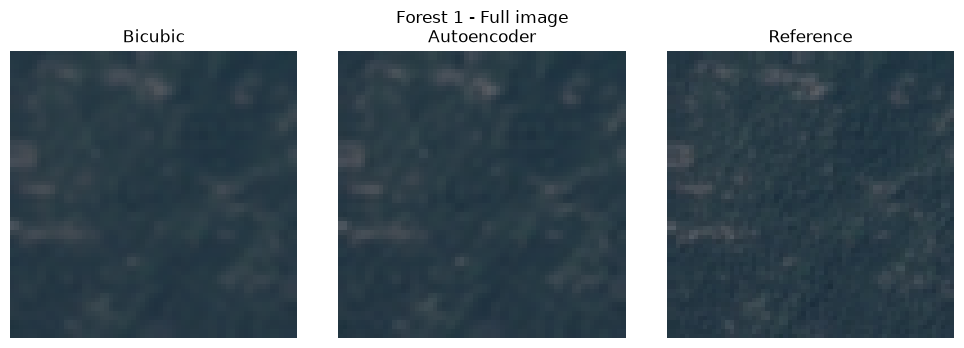

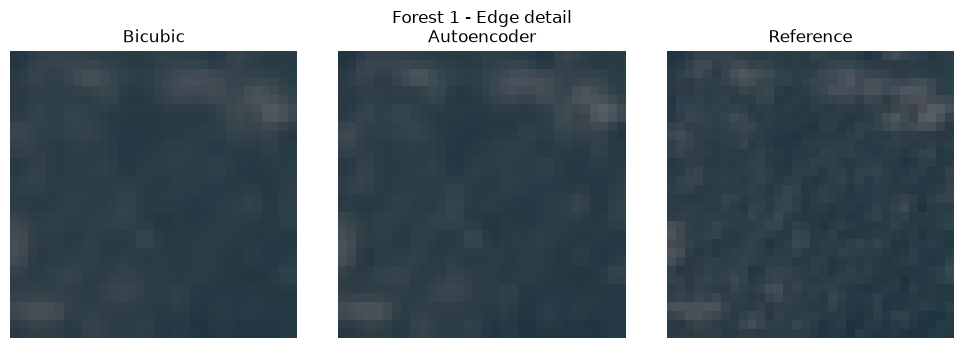

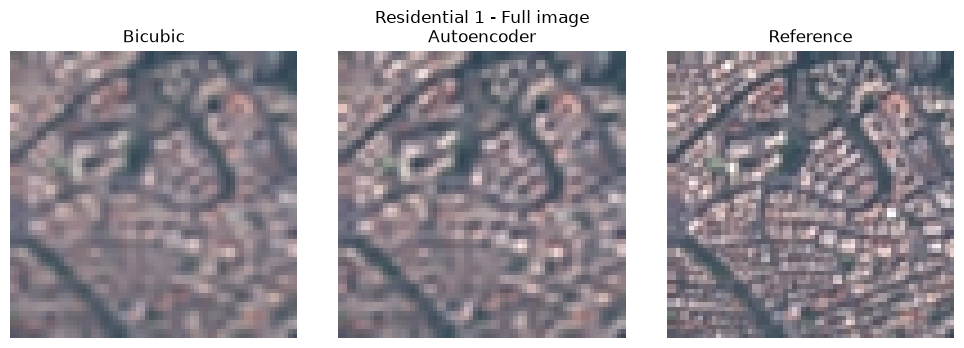

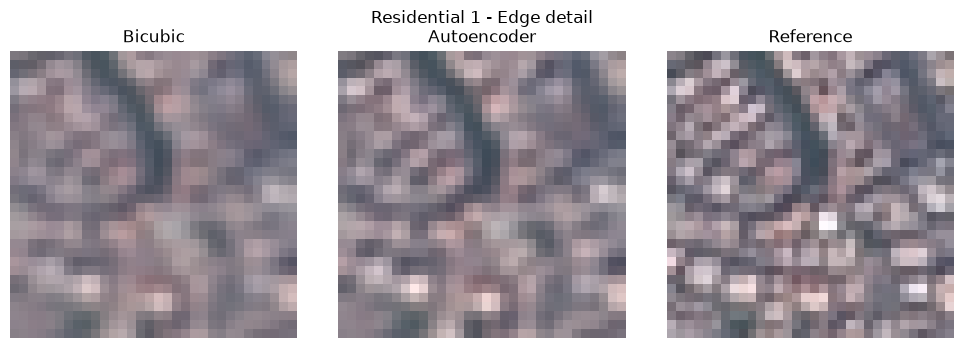

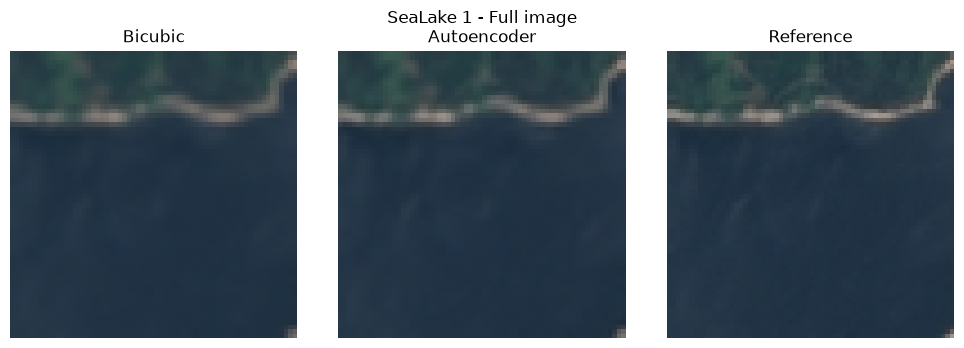

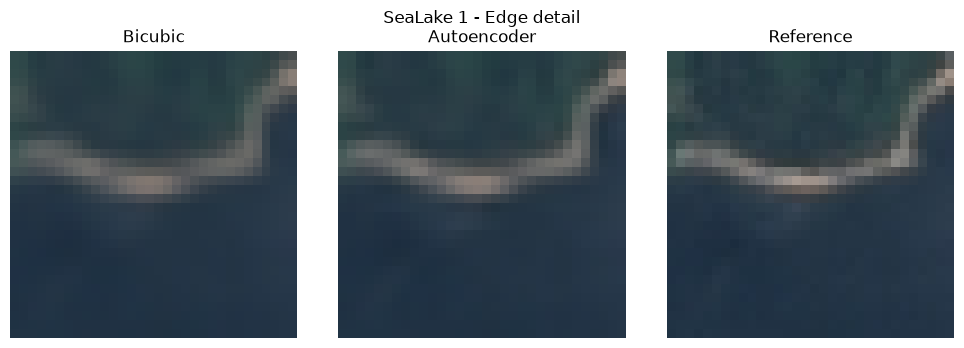

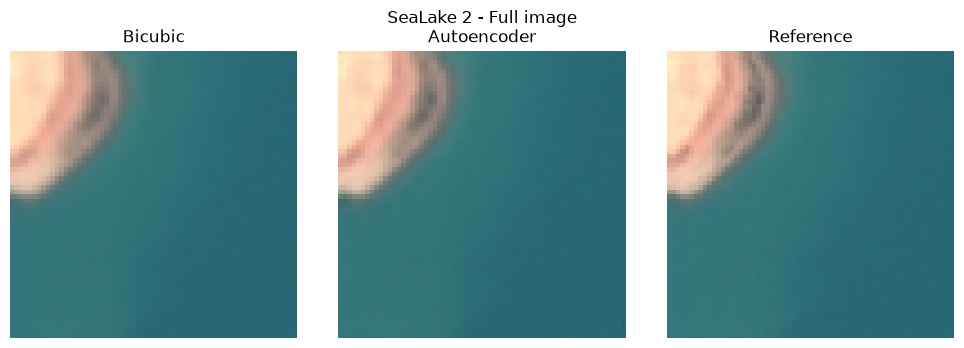

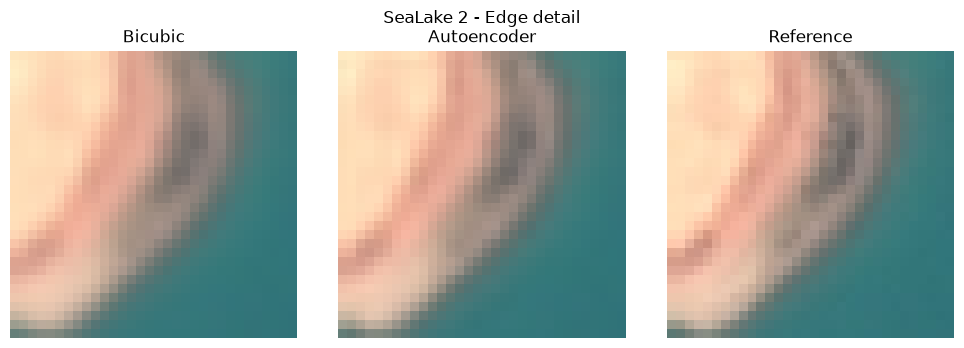

In [17]:
import pandas as pd
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

reconstructed = np.clip(autoencoder.predict(sr_test, batch_size=32, verbose=0), 0, 1)
metrics = []
for method, predictions in [('Bicubic', sr_test), ('Autoencoder', reconstructed)]:
    psnr = [peak_signal_noise_ratio(reference, prediction, data_range=1)
            for reference, prediction in zip(X_test, predictions)]
    ssim = [structural_similarity(reference, prediction, data_range=1, channel_axis=-1)
            for reference, prediction in zip(X_test, predictions)]
    for label, name in [(None, 'All'), *enumerate(CLASSES)]:
        mask = np.ones(len(y_test), dtype=bool) if label is None else y_test == label
        metrics.append({
            'method': method, 'class': name,
            'PSNR (dB)': np.mean(np.array(psnr)[mask]),
            'SSIM': np.mean(np.array(ssim)[mask]),
        })
display(pd.DataFrame(metrics).set_index(['method', 'class']).round(4))


from scipy.ndimage import uniform_filter

for label, name in enumerate(CLASSES):
    indices = detailed_indices(X_test, y_test, label, count=2 if label == 2 else 1)
    for example, index in enumerate(indices, 1):
        gy, gx = np.gradient(X_test[index].mean(axis=-1))
        edges = uniform_filter(np.hypot(gx, gy), size=32)
        row, column = np.unravel_index(np.argmax(edges[16:49, 16:49]), (33, 33))
        regions = [
            ((slice(None), slice(None)), 'Full image'),
            ((slice(row, row+32), slice(column, column+32)), 'Edge detail'),
        ]
        for region, view in regions:
            fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
            for ax, (image, title) in zip(axes, [
                (sr_test[index], 'Bicubic'),
                (reconstructed[index], 'Autoencoder'),
                (X_test[index], 'Reference'),
            ]):
                ax.imshow(image[region], interpolation='nearest')
                ax.set_title(title)
                ax.axis('off')
            fig.suptitle(f'{name} {example} - {view}')
            plt.tight_layout()
            plt.show()

## Conclusions

The first three PCA components explained 82.8% of the variance. Residential patches were partly separated and Forest and SeaLake partially overlapped.
The autoencoder increased mean test PSNR from 41.03 dB to 41.38 dB and SSIM from 0.9194 to 0.9337 compared with bicubic interpolation.
Residential patches got the biggest improvement, smooth SeaLake images already had high bicubic scores and only slightly benefited.
The differences are not dramatic (shorelines and building textures are blurred). This experiment measures reconstruction of synthetically degraded images, not a higher physical sensor resolution.
More diverse training data, longer training monitored on validation data and an edge-aware loss could all help preserve fine structures.